<a href="https://colab.research.google.com/github/JaafarBK02/satellite-cnn-vit/blob/main/01_explore_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/ermongroup/tile2vec.git

Cloning into 'tile2vec'...
remote: Enumerating objects: 240, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 240 (delta 34), reused 33 (delta 33), pack-reused 196 (from 1)
Receiving objects: 100% (240/240), 8.84 MiB | 14.93 MiB/s, done.
Resolving deltas: 100% (87/87), done.


In [2]:
!ls tile2vec
!ls tile2vec/data

data  environment.yml  examples  LICENSE  models  README.md  src
example_tiles  large_naip  tiles.zip


In [3]:
!cd tile2vec/data && unzip -q tiles.zip
!ls tile2vec/data
!ls tile2vec/data/tiles | head
!ls tile2vec/data/tiles | wc -l
!ls tile2vec/models tile2vec/examples tile2vec/data/large_naip tile2vec/data/example_tiles

example_tiles  large_naip  tiles  tiles.zip
1000tile.npy
100tile.npy
101tile.npy
102tile.npy
103tile.npy
104tile.npy
105tile.npy
106tile.npy
107tile.npy
108tile.npy
1001
tile2vec/data/example_tiles:
0anchor.npy	13anchor.npy	17anchor.npy	2anchor.npy    6anchor.npy
0distant.npy	13distant.npy	17distant.npy	2distant.npy   6distant.npy
0neighbor.npy	13neighbor.npy	17neighbor.npy	2neighbor.npy  6neighbor.npy
10anchor.npy	14anchor.npy	18anchor.npy	3anchor.npy    7anchor.npy
10distant.npy	14distant.npy	18distant.npy	3distant.npy   7distant.npy
10neighbor.npy	14neighbor.npy	18neighbor.npy	3neighbor.npy  7neighbor.npy
11anchor.npy	15anchor.npy	19anchor.npy	4anchor.npy    8anchor.npy
11distant.npy	15distant.npy	19distant.npy	4distant.npy   8distant.npy
11neighbor.npy	15neighbor.npy	19neighbor.npy	4neighbor.npy  8neighbor.npy
12anchor.npy	16anchor.npy	1anchor.npy	5anchor.npy    9anchor.npy
12distant.npy	16distant.npy	1distant.npy	5distant.npy   9distant.npy
12neighbor.npy	16neighbor.npy	1neighbor.

In [5]:

!cat tile2vec/models/README.md
!head -60 tile2vec/README.md

Download the pre-trained NAIP Tile2Vec model here.
# tile2vec
Implementation and examples for Tile2Vec

## Getting data

Follow the follow instructions for getting the necessary data for the provided examples.

### Getting pre-trained NAIP model

To get a Tile2Vec model that has been pre-trained on the NAIP dataset, download the weights provided [here](https://www.dropbox.com/s/bvzriiqlcof5lol/naip_trained.ckpt?dl=0) and save the file in the models directory: `tile2vec/models/naip_trained.ckpt`.

### Getting tiles
Unzip `data/tiles.zip` in the data directory, i.e., `tile2vec/data/tiles`. Within this folder, you should find 1000 tiles saved as Numpy arrays named `{1-1000}tile.npy` and 1 file named `y.npy` that contains the CDL labels corresponding to these 1000 tiles. 

### Getting triplets
Download tile triplet dataset for the training example [here](https://www.dropbox.com/s/afw3cbvo7sjerru/triplets.zip?dl=0) and then unzip in the data directory, i.e., `tile2vec/data/triplets`. This d

In [6]:
import numpy as np

tile = np.load('tile2vec/data/tiles/1tile.npy')
y = np.load('tile2vec/data/tiles/y.npy')
big = np.load('tile2vec/data/large_naip/naip1.npy')

print('tile shape:', tile.shape, tile.dtype, tile.min(), tile.max())
print('labels shape:', y.shape, 'unique classes:', len(np.unique(y)))
print('large image shape:', big.shape)

tile shape: (50, 50, 5) uint8 38 196
labels shape: (1000,) unique classes: 28
large image shape: (256, 256, 5)


In [7]:
for c in range(5):
    ch = tile[:, :, c]
    print(f'channel {c}: min={ch.min()} max={ch.max()} unique values={len(np.unique(ch))}')

channel 0: min=38 max=189 unique values=151
channel 1: min=46 max=178 unique values=133
channel 2: min=65 max=159 unique values=95
channel 3: min=63 max=196 unique values=117
channel 4: min=69 max=69 unique values=1


In [8]:
for i in range(1, 11):
    t = np.load(f'tile2vec/data/tiles/{i}tile.npy')
    print(i, 'channel 4 values:', np.unique(t[:, :, 4]), ' y:', y[i-1])

1 channel 4 values: [69]  y: 69.0
2 channel 4 values: [69]  y: 69.0
3 channel 4 values: [69]  y: 69.0
4 channel 4 values: [69 75]  y: 69.0
5 channel 4 values: [69 75]  y: 69.0
6 channel 4 values: [176]  y: 176.0
7 channel 4 values: [176]  y: 176.0
8 channel 4 values: [123]  y: 123.0
9 channel 4 values: [75]  y: 75.0
10 channel 4 values: [75]  y: 75.0


class 69: 354 tiles
class 176: 173 tiles
class 75: 167 tiles
class 123: 64 tiles
class 61: 58 tiles
class 36: 37 tiles
class 122: 25 tiles
class 121: 23 tiles
class 225: 13 tiles
class 24: 11 tiles


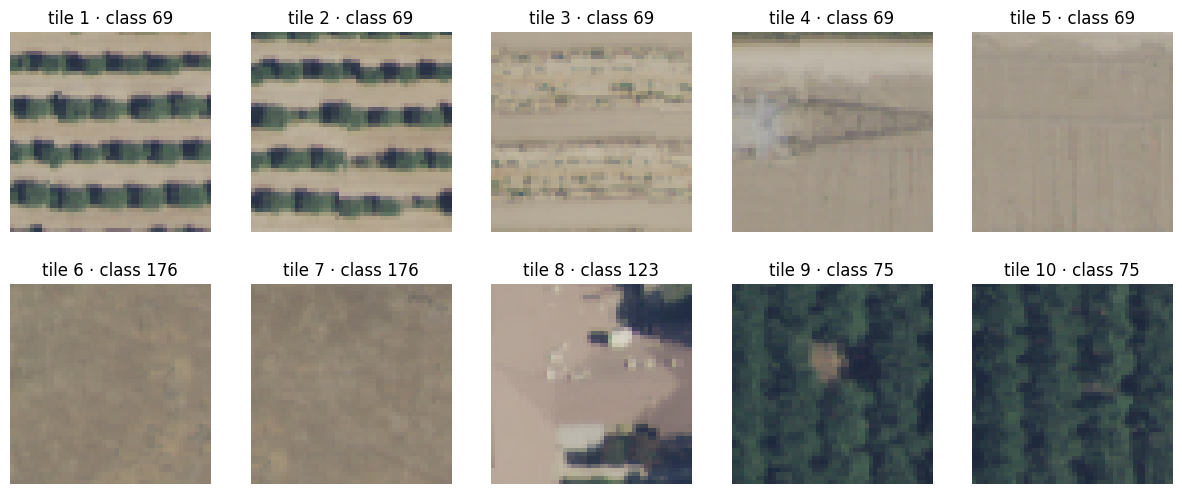

In [9]:
import matplotlib.pyplot as plt

classes, counts = np.unique(y, return_counts=True)
order = np.argsort(-counts)
for c, n in zip(classes[order][:10], counts[order][:10]):
    print(f'class {int(c)}: {n} tiles')

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, i in zip(axes.flat, range(1, 11)):
    t = np.load(f'tile2vec/data/tiles/{i}tile.npy')
    ax.imshow(t[:, :, :3])
    ax.set_title(f'tile {i} · class {int(y[i-1])}')
    ax.axis('off')
plt.show()

In [12]:
!grep -rn "http" tile2vec/models/README.md tile2vec/README.md
!grep -rn "ckpt" tile2vec --include=*.ipynb --include=*.py --include=*.md | head

tile2vec/README.md:10:To get a Tile2Vec model that has been pre-trained on the NAIP dataset, download the weights provided [here](https://www.dropbox.com/s/bvzriiqlcof5lol/naip_trained.ckpt?dl=0) and save the file in the models directory: `tile2vec/models/naip_trained.ckpt`.
tile2vec/README.md:16:Download tile triplet dataset for the training example [here](https://www.dropbox.com/s/afw3cbvo7sjerru/triplets.zip?dl=0) and then unzip in the data directory, i.e., `tile2vec/data/triplets`. This directory contains 100k tile triplets, with each triplet identified by its index and "anchor", "neighbor", or "distant".
tile2vec/README.md:10:To get a Tile2Vec model that has been pre-trained on the NAIP dataset, download the weights provided [here](https://www.dropbox.com/s/bvzriiqlcof5lol/naip_trained.ckpt?dl=0) and save the file in the models directory: `tile2vec/models/naip_trained.ckpt`.
tile2vec/examples/Example 3 - Tile2Vec features for CDL classification.ipynb:189:    "model_fn = '../models

In [13]:
!wget -q -O tile2vec/models/naip_trained.ckpt "https://www.dropbox.com/s/bvzriiqlcof5lol/naip_trained.ckpt?dl=1"
!ls -lh tile2vec/models

total 122M
-rw-r--r-- 1 root root 122M Nov 18 16:58 naip_trained.ckpt
-rw-r--r-- 1 root root   51 Nov 18 16:47 README.md


In [14]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/drive/MyDrive/tile2vec_data
!wget -q -O /content/drive/MyDrive/tile2vec_data/triplets.zip "https://www.dropbox.com/s/afw3cbvo7sjerru/triplets.zip?dl=1"
!ls -lh /content/drive/MyDrive/tile2vec_data

Mounted at /content/drive
total 2.2G
-rw------- 1 root root 2.2G Nov 18 17:01 triplets.zip


In [15]:
!ls tile2vec/src
!grep -n "def \|class \|z_dim\|in_channels" tile2vec/src/tilenet.py
!grep -n "make_tilenet\|z_dim\|in_channels\|load_state_dict\|encode\|255\|moveaxis\|bands" "tile2vec/examples/Example 3 - Tile2Vec features for CDL classification.ipynb"

cdl.py	     data_utils.py  sample_tiles.py  training.py
datasets.py  resnet.py	    tilenet.py
12:class ResidualBlock(nn.Module):
13:    def __init__(self, in_planes, planes, stride=1):
30:    def forward(self, x):
38:class TileNet(nn.Module):
39:    def __init__(self, num_blocks, in_channels=4, z_dim=512):
41:        self.in_channels = in_channels
42:        self.z_dim = z_dim
45:        self.conv1 = nn.Conv2d(self.in_channels, 64, kernel_size=3, stride=1,
52:        self.layer5 = self._make_layer(self.z_dim, num_blocks[4],
55:    def _make_layer(self, planes, num_blocks, stride, no_relu=False):
63:    def encode(self, x):
74:    def forward(self, x):
77:    def triplet_loss(self, z_p, z_n, z_d, margin=0.1, l2=0):
90:    def loss(self, patch, neighbor, distant, margin=0.1, l2=0):
99:def make_tilenet(in_channels=4, z_dim=512):
105:    return TileNet(num_blocks, in_channels=in_channels, z_dim=z_dim)
25:    "from src.tilenet import make_tilenet\n",
44:    "in_channels = 4\n",
45:    "z_di

In [17]:
import sys, torch
import numpy as np
sys.path.append('tile2vec')                      # lets Python find the authors' src/ folder
from src.tilenet import make_tilenet

device = 'cuda' if torch.cuda.is_available() else 'cpu'
tilenet = make_tilenet(in_channels=4, z_dim=512) # build the empty CNN (random weights)
state = torch.load('tile2vec/models/naip_trained.ckpt', map_location=device)
tilenet.load_state_dict(state, strict=False)     # strict=False ignores the unexpected linear layers
tilenet.to(device).eval()                        # eval = use mode, not training mode

X = np.zeros((1000, 512))                        # one row of 512 numbers per tile
with torch.no_grad():                            # no training, so no gradients needed
    for i in range(1000):
        t = np.load(f'tile2vec/data/tiles/{i+1}tile.npy')[:, :, :4]   # drop channel 4 (labels!)
        t = np.moveaxis(t, -1, 0) / 255                                # (4,50,50), scaled 0–1
        t = torch.from_numpy(t).float().unsqueeze(0).to(device)       # add batch dim → (1,4,50,50)
        X[i] = tilenet.encode(t).cpu().numpy()                        # 512-number embedding

print('embeddings:', X.shape)
print('first tile, first 5 numbers:', X[0, :5])

embeddings: (1000, 512)
first tile, first 5 numbers: [5.38646698 4.04911184 0.         0.         0.        ]


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0)

dummy = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
rf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1).fit(X_tr, y_tr)

for name, model in [('Always "grapes" (dumb baseline)', dummy), ('Tile2Vec + Random Forest', rf)]:
    p = model.predict(X_te)
    print(f'{name}: accuracy = {accuracy_score(y_te, p):.3f}, macro F1 = {f1_score(y_te, p, average="macro"):.3f}')

Always "grapes" (dumb baseline): accuracy = 0.365, macro F1 = 0.023
Tile2Vec + Random Forest: accuracy = 0.735, macro F1 = 0.351


In [19]:
!grep -n "RandomForest\|LogisticRegression\|train_test_split\|n_trials\|accuracy\|test_size" "tile2vec/examples/Example 3 - Tile2Vec features for CDL classification.ipynb"

277:    "from sklearn.ensemble import RandomForestClassifier\n",
278:    "from sklearn.model_selection import train_test_split"
329:    "We can randomly split the data and train a random forest classifier many times to get an estimate of the average accuracy."
341:      "Mean accuracy: 0.6876\n",
347:    "n_trials = 100\n",
348:    "accs = np.zeros((n_trials,))\n",
349:    "for i in range(n_trials):\n",
351:    "    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2)\n",
352:    "    rf = RandomForestClassifier()\n",
355:    "print('Mean accuracy: {:0.4f}'.format(accs.mean()))\n",


In [20]:
def evaluate(X, y, n_trials=100, n_trees=100):
    accs, f1s = [], []
    for i in range(n_trials):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=i)
        rf = RandomForestClassifier(n_estimators=n_trees, n_jobs=-1, random_state=i).fit(X_tr, y_tr)
        p = rf.predict(X_te)
        accs.append(accuracy_score(y_te, p))
        f1s.append(f1_score(y_te, p, average='macro'))
    return np.mean(accs), np.std(accs), np.mean(f1s)

for trees in [10, 100]:
    acc, sd, f1 = evaluate(X, y, n_trees=trees)
    print(f'{trees} trees: accuracy = {acc:.4f} ± {sd:.4f}, macro F1 = {f1:.3f}')

10 trees: accuracy = 0.6853 ± 0.0296, macro F1 = 0.345
100 trees: accuracy = 0.7174 ± 0.0272, macro F1 = 0.394


In [21]:
np.save('/content/drive/MyDrive/tile2vec_data/X_pretrained.npy', X)